In [1]:
import pandas as pd
from pathlib import Path

# Load the Superstore dataset
file_path = Path("data/raw/archive/Sample - Superstore.csv")
df = pd.read_csv(file_path, encoding="latin1")

# Display dataset size and first rows
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [2]:
print("Missing values:")
display(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nData types:")
display(df.dtypes)

Missing values:


Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


Duplicate rows: 0

Data types:


Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

In [3]:
# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

# Convert date columns to datetime
df["Order Date"] = pd.to_datetime(df["Order Date"], format="mixed")
df["Ship Date"] = pd.to_datetime(df["Ship Date"], format="mixed")

# Check data types after conversion
print("\nUpdated date types:")
print(df[["Order Date", "Ship Date"]].dtypes)

# Validate numerical values
print("\nSales and Profit summary:")
display(df[["Sales", "Profit", "Discount", "Quantity"]].describe())

# Confirm dataset dimensions
print("\nFinal dataset shape:", df.shape)

Duplicate rows: 0

Updated date types:
Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object

Sales and Profit summary:


,Sales,Profit,Discount,Quantity
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,28.656896,0.156203,3.789574
std,623.245101,234.260108,0.206452,2.225110
min,0.444000,-6599.978000,0.000000,1.000000
25%,17.280000,1.728750,0.000000,2.000000
50%,54.490000,8.666500,0.200000,3.000000
75%,209.940000,29.364000,0.200000,5.000000
max,22638.480000,8399.976000,0.800000,14.000000



Final dataset shape: (9994, 21)


In [4]:
# Overall business performance
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
total_orders = df["Order ID"].nunique()
total_quantity = df["Quantity"].sum()

print(f"Total Sales: ${total_sales:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")
print(f"Unique Orders: {total_orders:,}")
print(f"Units Sold: {total_quantity:,}")

# Sales and profit by region
region_summary = (
    df.groupby("Region")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
    .sort_values("Sales", ascending=False)
)

print("\nSales and Profit by Region:")
display(region_summary.round(2))

# Sales and profit by category
category_summary = (
    df.groupby("Category")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
    .sort_values("Sales", ascending=False)
)

print("\nSales and Profit by Category:")
display(category_summary.round(2))

Total Sales: $2,297,200.86
Total Profit: $286,397.02
Unique Orders: 5,009
Units Sold: 37,873

Sales and Profit by Region:


,Sales,Profit
Region,,
West,725457.82,108418.45
East,678781.24,91522.78
Central,501239.89,39706.36
South,391721.90,46749.43



Sales and Profit by Category:


,Sales,Profit
Category,,
Technology,836154.03,145454.95
Furniture,741999.80,18451.27
Office Supplies,719047.03,122490.80


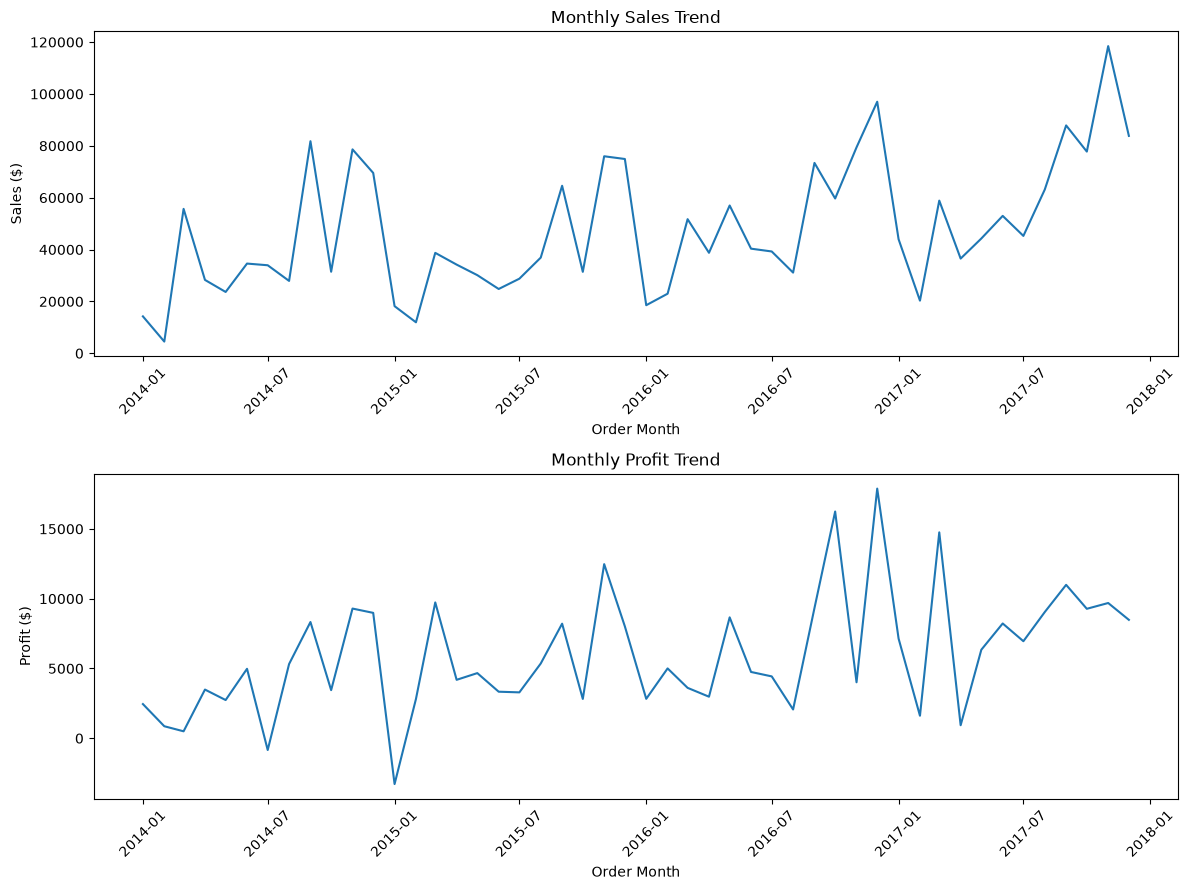

,Order Month,Sales,Profit
0,2014-01-01,14236.895,2450.1907
1,2014-02-01,4519.892,862.3084
2,2014-03-01,55691.009,498.7299
3,2014-04-01,28295.345,3488.8352
4,2014-05-01,23648.287,2738.7096


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Aggregate sales and profit by month
df["Order Month"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()

monthly_summary = (
    df.groupby("Order Month")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum")
    )
    .reset_index()
)

# Plot monthly sales and profit
fig, axes = plt.subplots(2, 1, figsize=(12, 9))

sns.lineplot(data=monthly_summary, x="Order Month", y="Sales", ax=axes[0])
axes[0].set_title("Monthly Sales Trend")
axes[0].set_xlabel("Order Month")
axes[0].set_ylabel("Sales ($)")
axes[0].tick_params(axis="x", rotation=45)

sns.lineplot(data=monthly_summary, x="Order Month", y="Profit", ax=axes[1])
axes[1].set_title("Monthly Profit Trend")
axes[1].set_xlabel("Order Month")
axes[1].set_ylabel("Profit ($)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

display(monthly_summary.head())

,Sales,Profit,Quantity
Sub-Category,,,
Tables,206965.53,-17725.48,1241
Bookcases,114880.00,-3472.56,868
Supplies,46673.54,-1189.10,647
Fasteners,3024.28,949.52,914
Machines,189238.63,3384.76,440
Labels,12486.31,5546.25,1400
Art,27118.79,6527.79,3000
Envelopes,16476.40,6964.18,906
Furnishings,91705.16,13059.14,3563


,Discount,Average_Profit,Total_Profit,Total_Sales,Records
0,0.00,66.90,320987.60,1087908.47,4798
1,0.10,96.06,9029.18,54369.35,94
2,0.15,27.29,1418.99,27558.52,52
3,0.20,24.70,90337.31,764594.37,3657
4,0.30,-45.68,-10369.28,103226.66,227
5,0.32,-88.56,-2391.14,14493.46,27
6,0.40,-111.93,-23057.05,116417.78,206
7,0.45,-226.65,-2493.11,5484.97,11
8,0.50,-310.70,-20506.43,58918.54,66
9,0.60,-43.08,-5944.66,6644.70,138


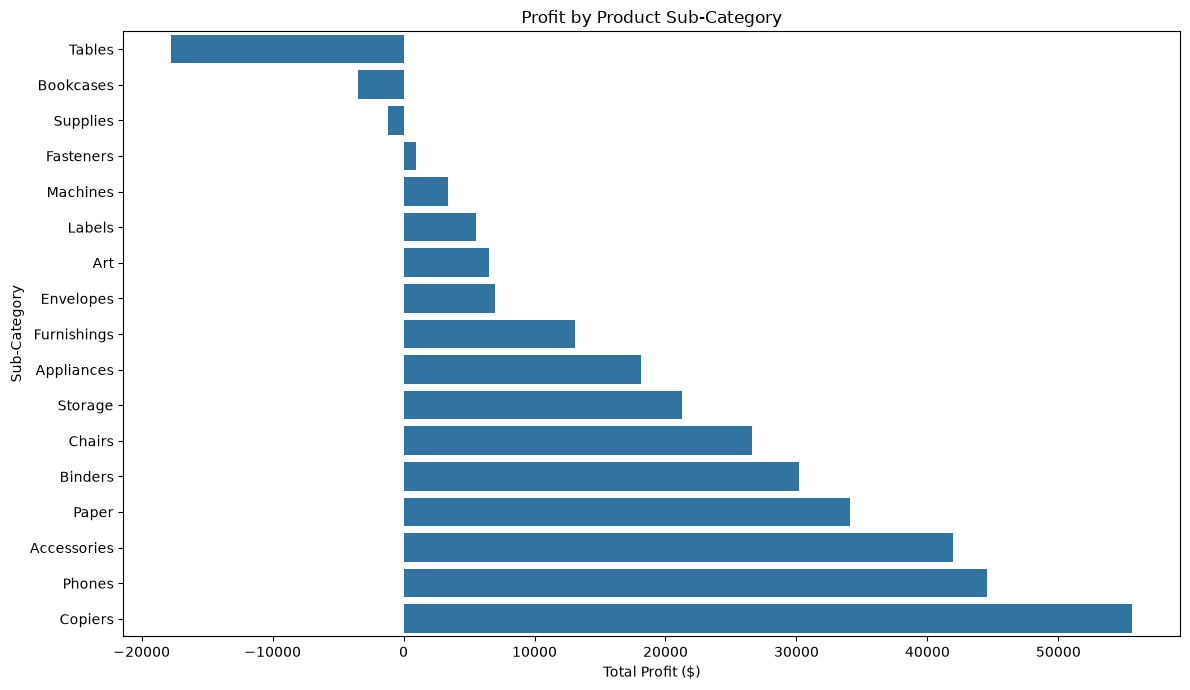

In [6]:
# Analyze sales and profit by sub-category
subcategory_summary = (
    df.groupby("Sub-Category")
    .agg(
        Sales=("Sales", "sum"),
        Profit=("Profit", "sum"),
        Quantity=("Quantity", "sum")
    )
    .sort_values("Profit", ascending=True)
)

display(subcategory_summary.round(2))

# Analyze how discount relates to profit
discount_summary = (
    df.groupby("Discount")
    .agg(
        Average_Profit=("Profit", "mean"),
        Total_Profit=("Profit", "sum"),
        Total_Sales=("Sales", "sum"),
        Records=("Profit", "count")
    )
    .reset_index()
    .sort_values("Discount")
)

display(discount_summary.round(2))

# Visualize profit by sub-category
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 7))
sns.barplot(
    data=subcategory_summary.reset_index(),
    x="Profit",
    y="Sub-Category"
)
plt.title("Profit by Product Sub-Category")
plt.xlabel("Total Profit ($)")
plt.ylabel("Sub-Category")
plt.tight_layout()
plt.show()

In [7]:
import pandas as pd
from scipy import stats

# Compare records with and without discounts
df["Discount Group"] = df["Discount"].apply(
    lambda x: "Discounted" if x > 0 else "No Discount"
)

discount_profit = df.groupby("Discount Group")["Profit"]

display(discount_profit.agg(["count", "mean", "median", "std"]).round(2))

# Welch's t-test compares the average profit of the two groups
discounted = df.loc[df["Discount"] > 0, "Profit"]
no_discount = df.loc[df["Discount"] == 0, "Profit"]

t_stat, p_value = stats.ttest_ind(
    discounted,
    no_discount,
    equal_var=False
)

print(f"T-statistic: {t_stat:.3f}")
print(f"P-value: {p_value:.6f}")

if p_value < 0.05:
    print("Result: The average profits differ statistically between the groups.")
else:
    print("Result: There is insufficient evidence of a difference in average profits.")

,count,mean,median,std
Discount Group,,,,
Discounted,5196,-6.66,3.34,204.81
No Discount,4798,66.90,16.00,257.06


T-statistic: -15.738
P-value: 0.000000
Result: The average profits differ statistically between the groups.
